# **Telco Customer Churn Analysis & Prediction**

# Aim
This project predicts customer churn from the Telco dataset by training and comparing several classification models, then picking the best performer.

## Load Data




In [3]:
import pandas as pd
df = pd.read_csv('/content/sample_data/Telco_Customer_Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Initial Data Inspection




In [29]:
print(df.dtypes)
print(df.isnull().sum())
df.info()

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
Mo

## Exploratory Data Analysis (EDA)



In [8]:
import numpy as np
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan).astype(float)
median_total_charges = df['TotalCharges'].median()
df['TotalCharges'].fillna(median_total_charges, inplace=True)
print("Verifying 'TotalCharges' data type and missing values:")
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isnull().sum())

Verifying 'TotalCharges' data type and missing values:
float64
0


/tmp/ipykernel_1560/577396208.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(median_total_charges, inplace=True)


In [9]:
import numpy as np
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan).astype(float)
median_total_charges = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_total_charges)
print("Verifying 'TotalCharges' data type and missing values:")
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].isnull().sum())

Verifying 'TotalCharges' data type and missing values:
float64
0



To visualize the distributions of numerical features, I will create histograms for 'tenure', 'MonthlyCharges', and 'TotalCharges' as per the subtask instructions. This will help in understanding their patterns and identifying any skewness or outliers.



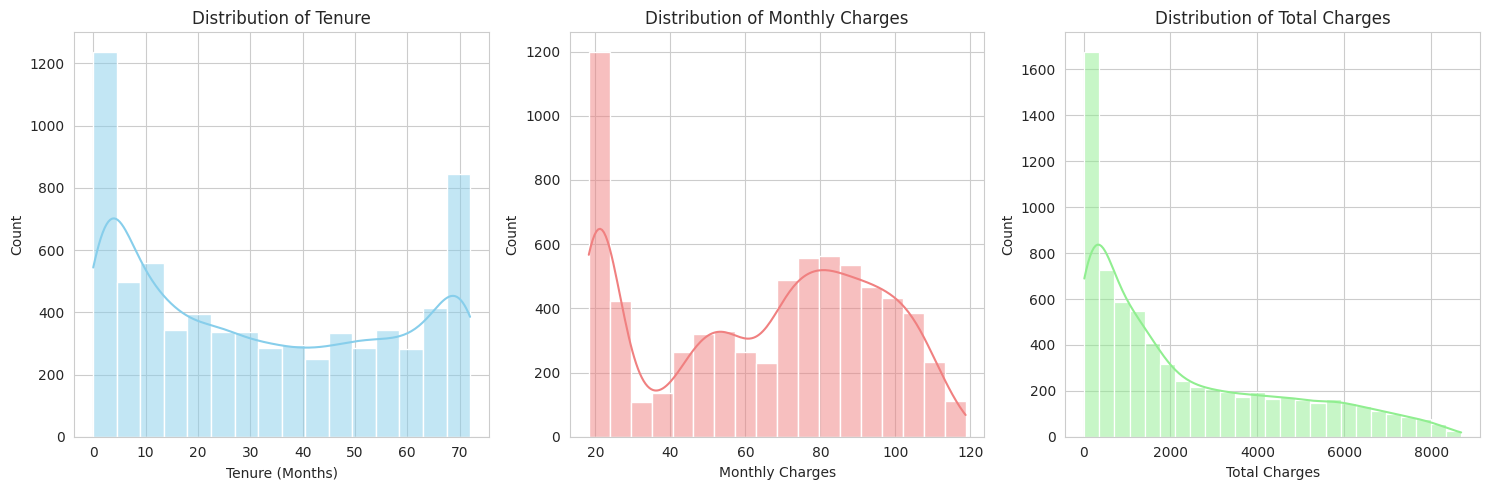

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
plt.figure(figsize=(15, 5))

# Histogram for 'tenure'
plt.subplot(1, 3, 1) # 1 row, 3 columns, 1st plot
sns.histplot(df['tenure'], kde=True, color='skyblue')
plt.title('Distribution of Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Count')

# Histogram for 'MonthlyCharges'
plt.subplot(1, 3, 2) # 1 row, 3 columns, 2nd plot
sns.histplot(df['MonthlyCharges'], kde=True, color='lightcoral')
plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges')
plt.ylabel('Count')

# Histogram for 'TotalCharges'
plt.subplot(1, 3, 3) # 1 row, 3 columns, 3rd plot
sns.histplot(df['TotalCharges'], kde=True, color='lightgreen')
plt.title('Distribution of Total Charges')
plt.xlabel('Total Charges')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


In [11]:
import warnings
warnings.filterwarnings("ignore")

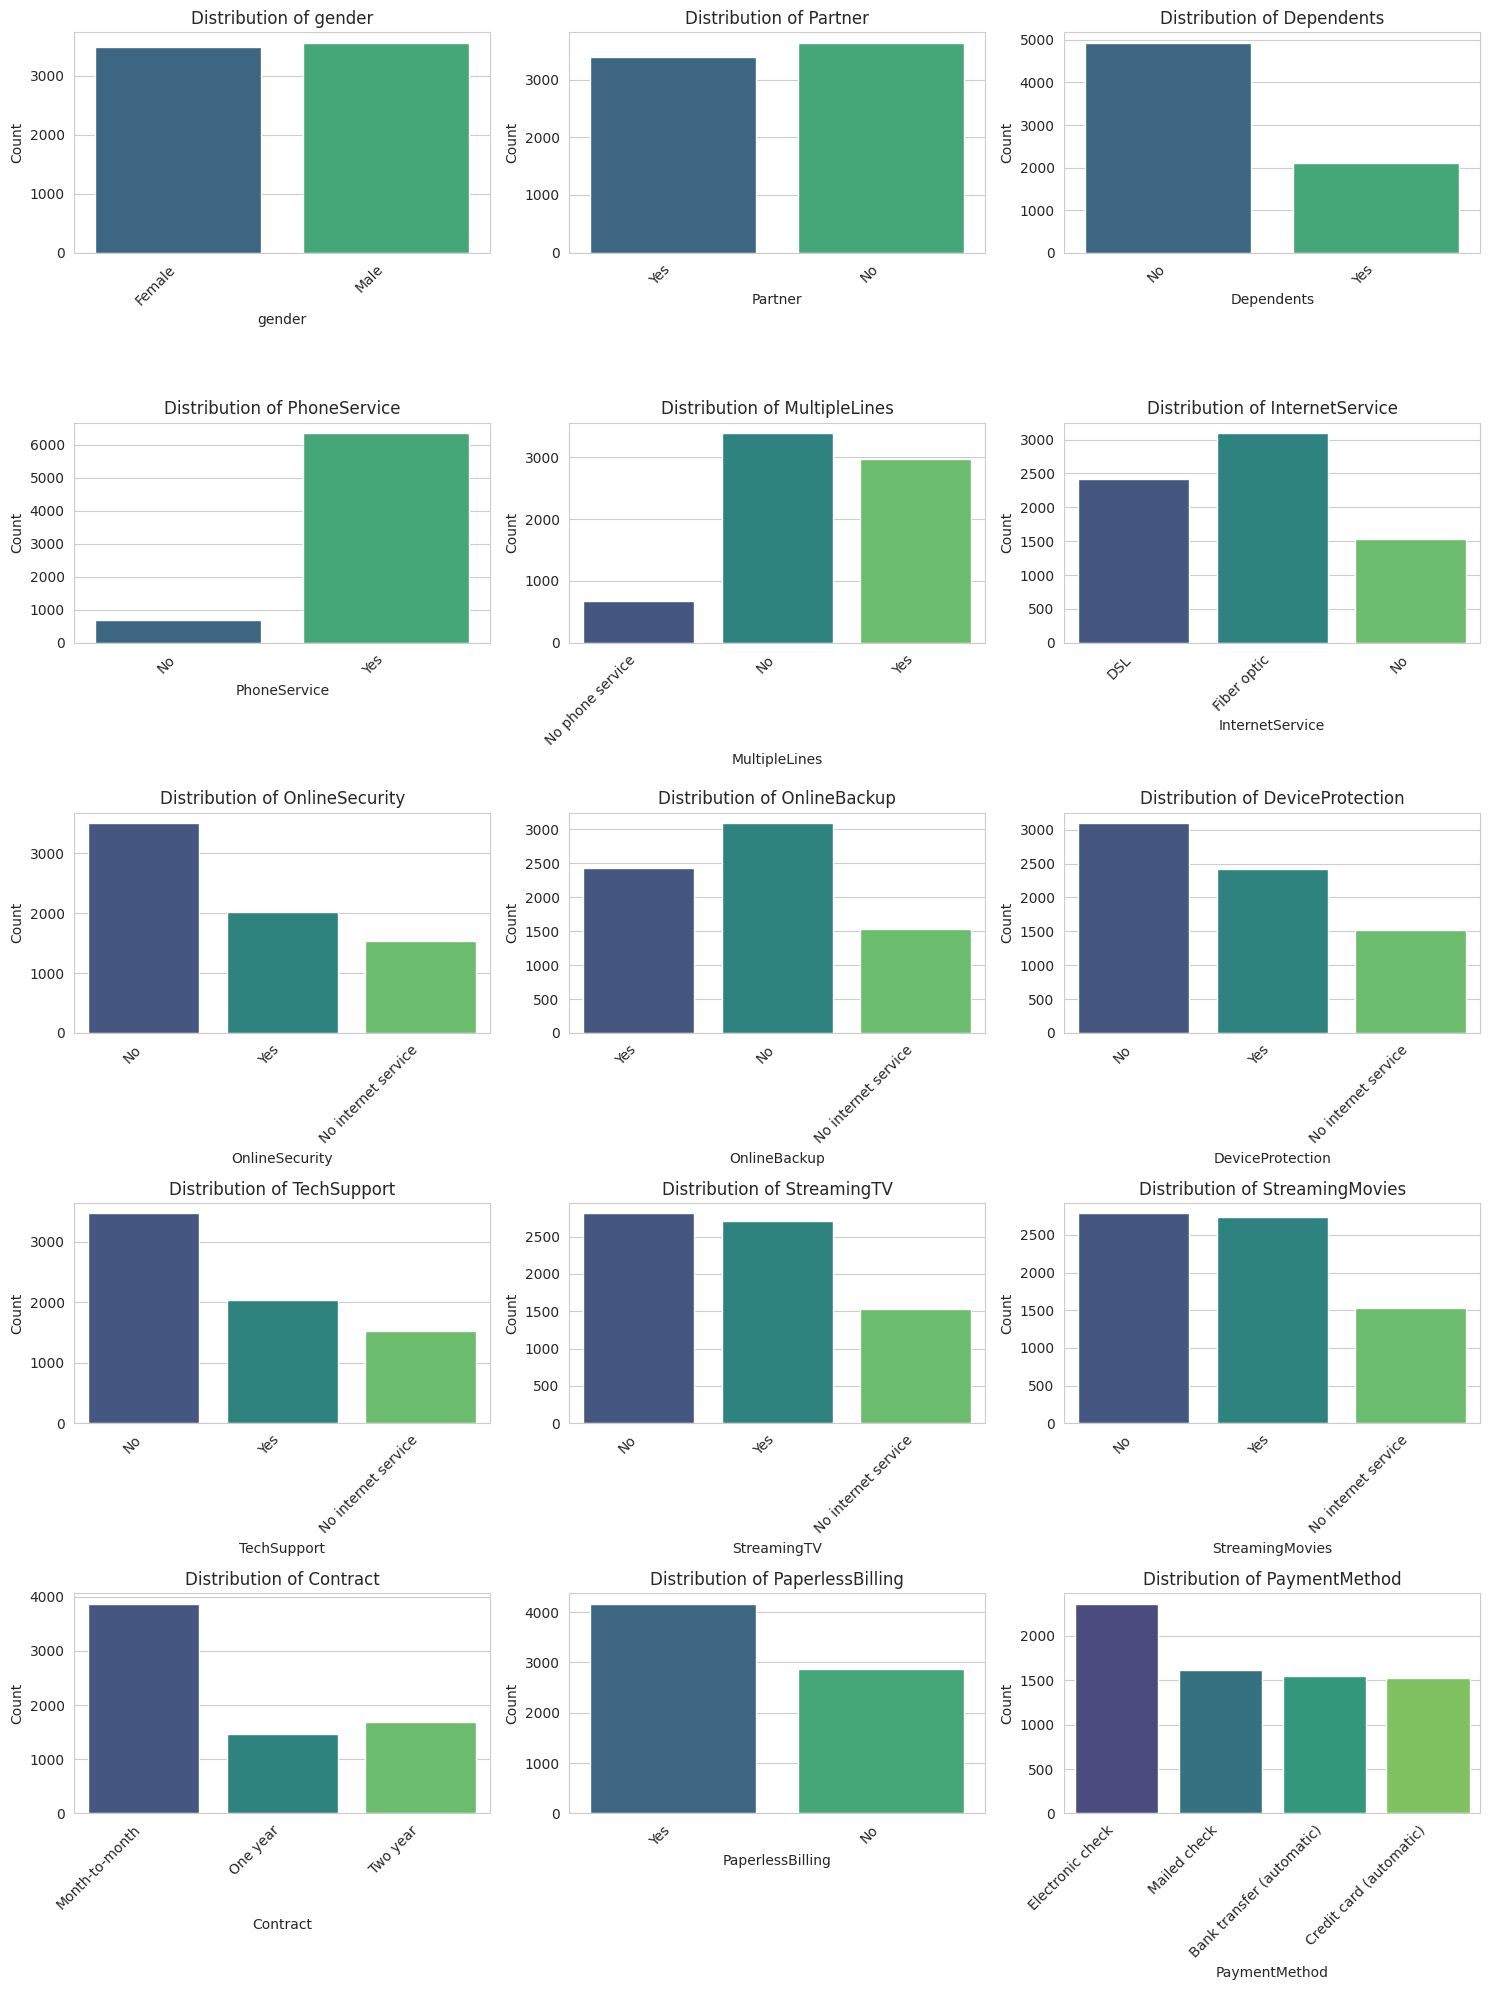

In [12]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()
categorical_cols.remove('customerID')
categorical_cols.remove('Churn')

n_cols = 3
n_rows = (len(categorical_cols) + n_cols - 1) // n_cols

plt.figure(figsize=(n_cols * 5, n_rows * 4))

for i, col in enumerate(categorical_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.countplot(data=df, x=col, hue=col, palette='viridis', legend=False)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()



To visualize the relationship between categorical features and the 'Churn' target variable, I will create count plots for each categorical column, using 'Churn' as the hue. This will display the distribution of 'Churn' for each category within the feature, allowing for an understanding of how each category influences churn.



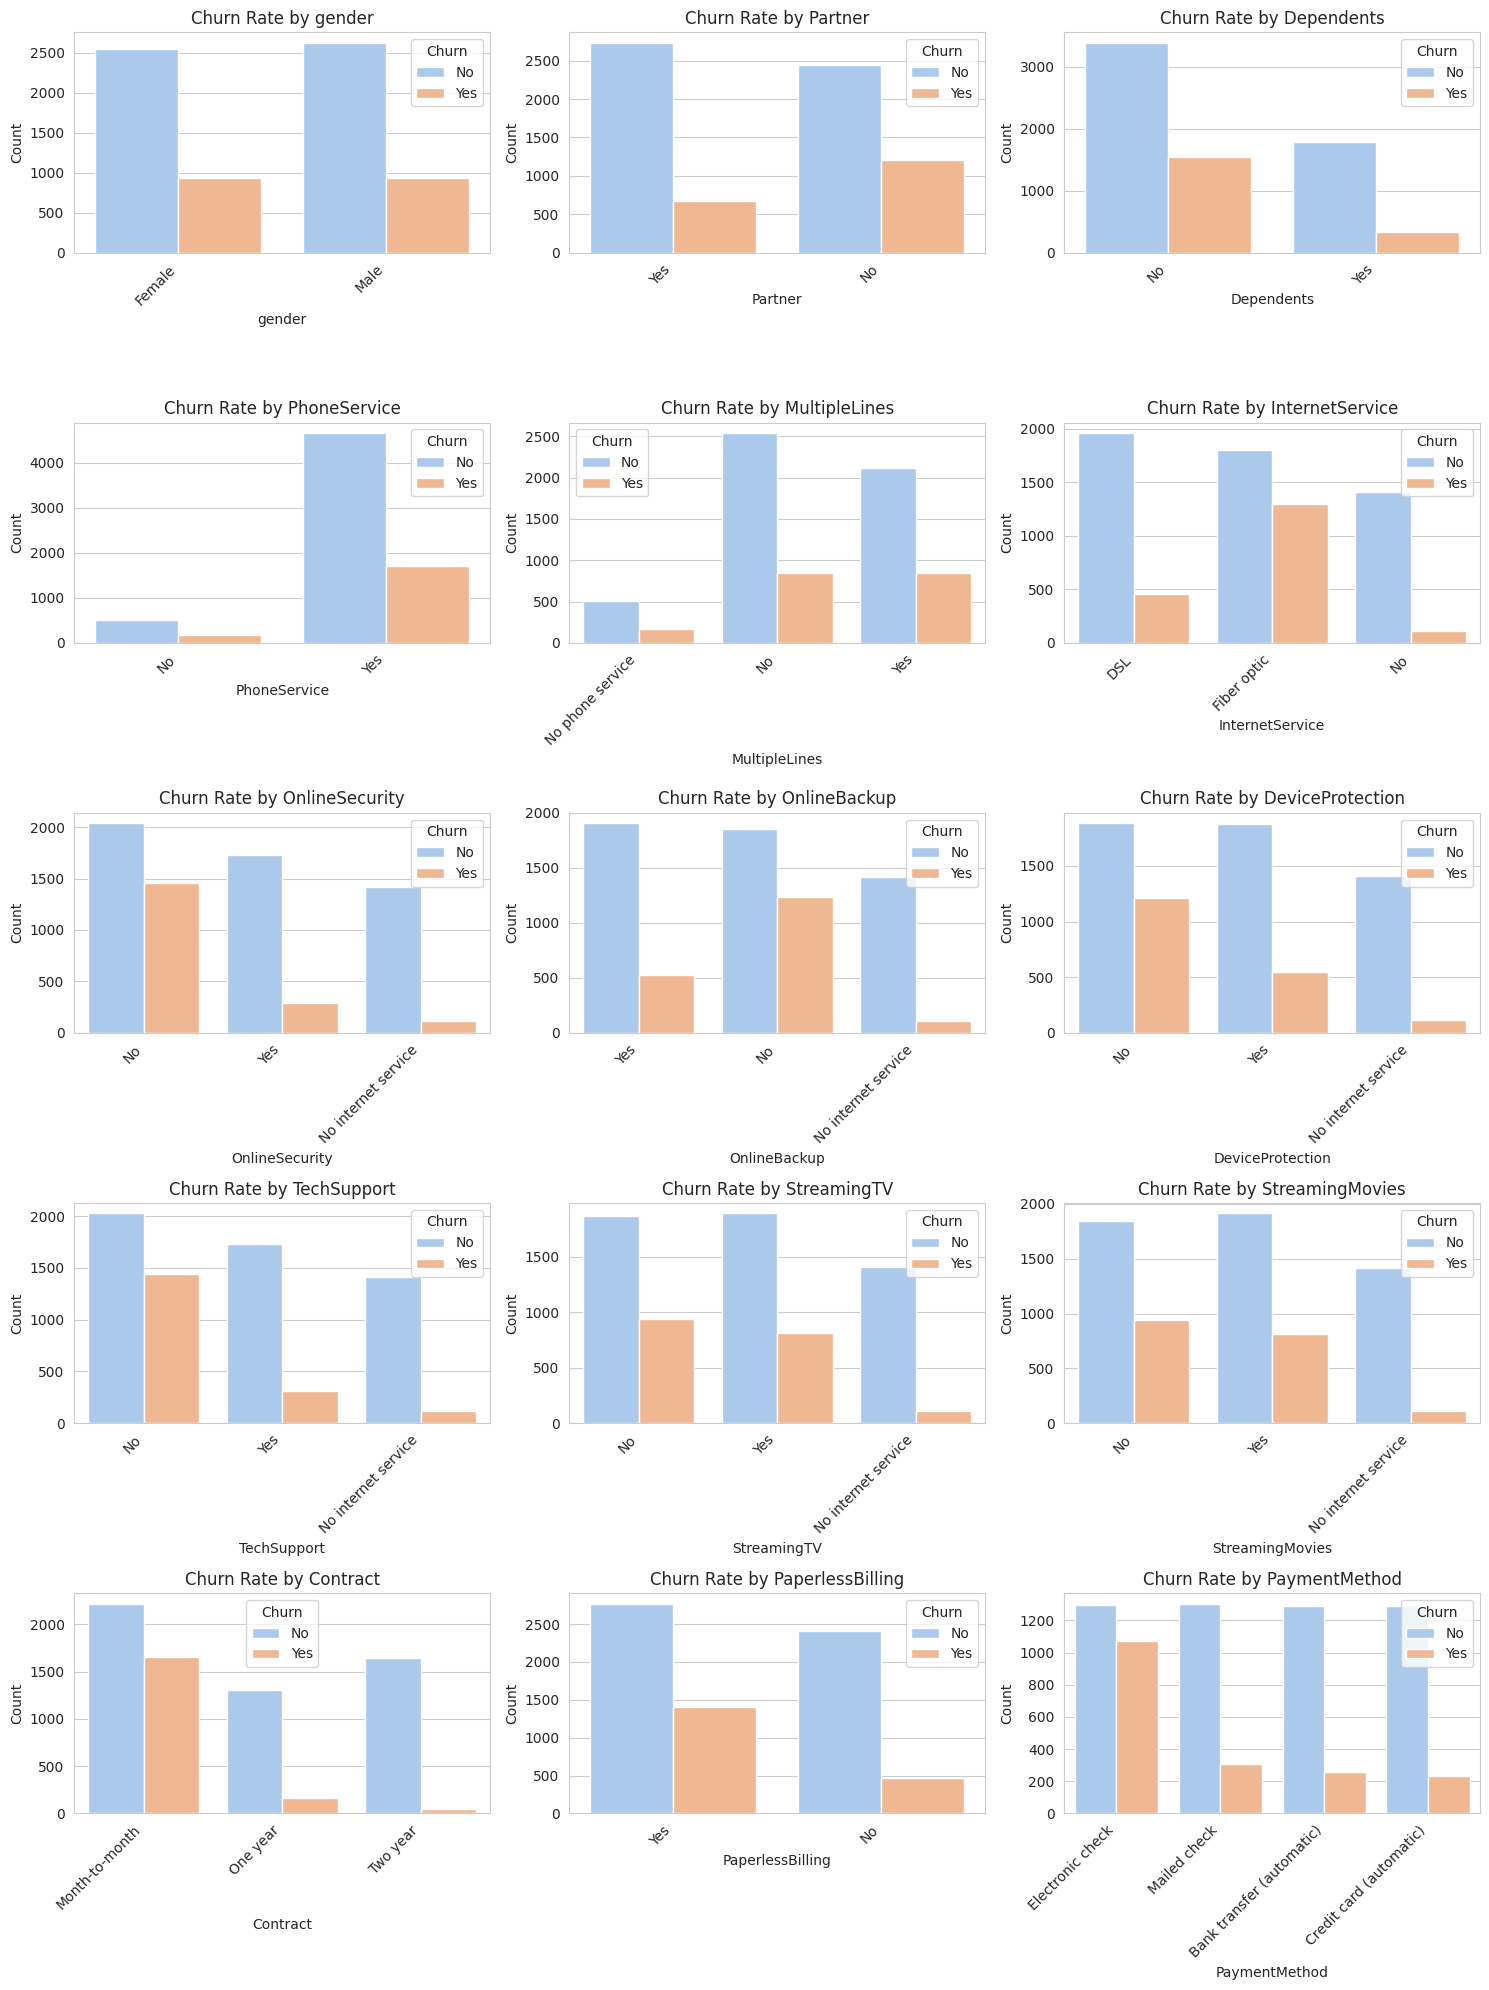

In [ ]:
n_cols = 3
n_rows = (len(categorical_cols) + n_cols - 1) // n_cols

plt.figure(figsize=(n_cols * 5, n_rows * 4))

for i, col in enumerate(categorical_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.countplot(data=df, x=col, hue='Churn', palette='pastel')
    plt.title(f'Churn Rate by {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Churn')

plt.tight_layout()
plt.show()

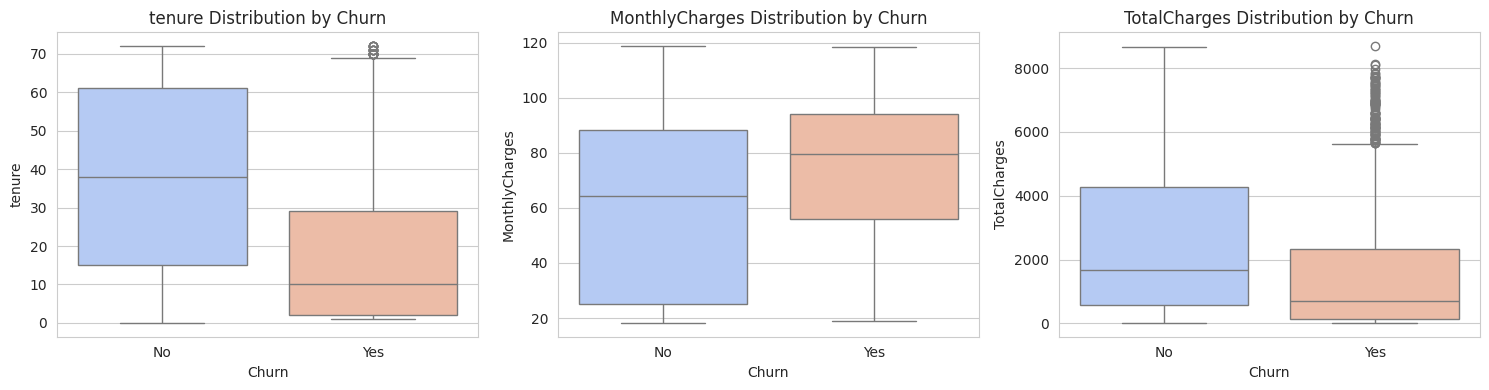

In [13]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
n_cols = 3
n_rows = (len(numerical_cols) + n_cols - 1) // n_cols

plt.figure(figsize=(n_cols * 5, n_rows * 4))

for i, col in enumerate(numerical_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(data=df, x='Churn', y=col, palette='coolwarm')
    plt.title(f'{col} Distribution by Churn')
    plt.xlabel('Churn')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

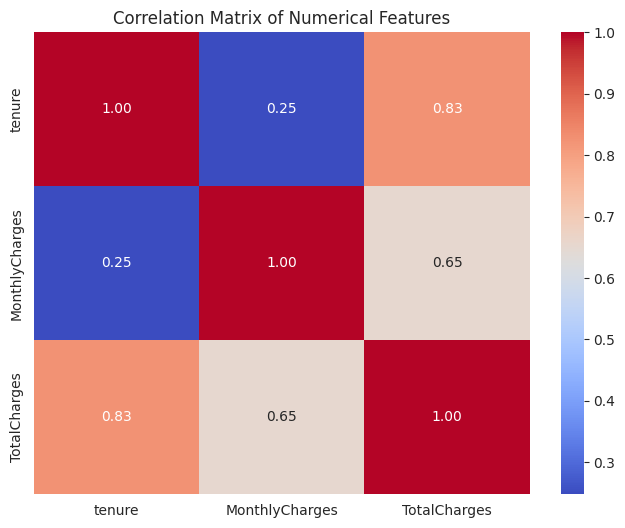

In [14]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()


## Data Preprocessing and Cleaning




In [15]:
df_processed = df.copy()
df_processed = df_processed.drop('customerID', axis=1)

# Convert 'Churn' to numerical (Yes=1, No=0)
df_processed['Churn'] = df_processed['Churn'].map({'Yes': 1, 'No': 0})

print("Dropped 'customerID' column and converted 'Churn' to numerical:")
print(df_processed[['customerID', 'Churn']].head() if 'customerID' in df_processed.columns else df_processed['Churn'].head())
print(f"'Churn' column data type: {df_processed['Churn'].dtype}")

Dropped 'customerID' column and converted 'Churn' to numerical:
0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64
'Churn' column data type: int64


## Feature Engineering




In [19]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
raw_addon_cols = [
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

existing_raw_cols = [col for col in raw_addon_cols if col in df_processed.columns]

if existing_raw_cols:
    df_processed['TotalAddonServices'] = df_processed[existing_raw_cols].apply(lambda x: x == 'Yes').sum(axis=1)
    print("Created 'TotalAddonServices' feature from raw columns.")
    scaler_addon = StandardScaler()
    df_processed['TotalAddonServices'] = scaler_addon.fit_transform(df_processed[['TotalAddonServices']])
    print("Scaled 'TotalAddonServices' feature.")
else:

    encoded_addon_cols = [col + '_Yes' for col in raw_addon_cols]
    existing_encoded_cols = [col for col in encoded_addon_cols if col in df_processed.columns]
    if existing_encoded_cols:
        df_processed['TotalAddonServices'] = df_processed[existing_encoded_cols].astype(int).sum(axis=1)
        scaler_addon = StandardScaler()
        df_processed['TotalAddonServices'] = scaler_addon.fit_transform(df_processed[['TotalAddonServices']])
        print("Created and scaled 'TotalAddonServices' feature from encoded columns.")
    else:
        print("Warning: None of the specified add-on service columns were found in the DataFrame.")

print("\nFirst few rows of df_processed with 'TotalAddonServices':")
print(df_processed[['TotalAddonServices']].head() if 'TotalAddonServices' in df_processed.columns else "Column not found")

Created 'TotalAddonServices' feature from raw columns.
Scaled 'TotalAddonServices' feature.

First few rows of df_processed with 'TotalAddonServices':
   TotalAddonServices
0           -0.713676
1           -0.224772
2           -0.224772
3            0.264131
4           -1.202579


In [20]:
import pandas as pd

categorical_cols_to_process = df_processed.select_dtypes(include='object').columns.tolist()

binary_cols = []
one_hot_cols = []

for col in categorical_cols_to_process:
    if df_processed[col].nunique() == 2:
        binary_cols.append(col)
    else:
        one_hot_cols.append(col)


for col in binary_cols:

    if col == 'gender':
        mapping = {'Female': 0, 'Male': 1}
    elif df_processed[col].isin(['No', 'Yes', 'No phone service', 'No internet service']).all():

        mapping = {'No': 0, 'Yes': 1, 'No phone service': 0, 'No internet service': 0}
    else:
        unique_vals = df_processed[col].unique()
        mapping = {unique_vals[0]: 0, unique_vals[1]: 1}

    df_processed[col] = df_processed[col].map(mapping).astype(int)
    print(f"Binary encoded column '{col}' to numerical values.")

if one_hot_cols:
    df_processed = pd.get_dummies(df_processed, columns=one_hot_cols, drop_first=True)
    print(f"One-hot encoded columns: {one_hot_cols}.")

for col in df_processed.select_dtypes(include='bool').columns:
    df_processed[col] = df_processed[col].astype(int)
    print(f"Converted boolean column '{col}' to int.")



Binary encoded column 'gender' to numerical values.
Binary encoded column 'Partner' to numerical values.
Binary encoded column 'Dependents' to numerical values.
Binary encoded column 'PhoneService' to numerical values.
Binary encoded column 'PaperlessBilling' to numerical values.
One-hot encoded columns: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod'].
Converted boolean column 'MultipleLines_No phone service' to int.
Converted boolean column 'MultipleLines_Yes' to int.
Converted boolean column 'InternetService_Fiber optic' to int.
Converted boolean column 'InternetService_No' to int.
Converted boolean column 'OnlineSecurity_No internet service' to int.
Converted boolean column 'OnlineSecurity_Yes' to int.
Converted boolean column 'OnlineBackup_No internet service' to int.
Converted boolean column 'OnlineBackup_Yes' to int.
Converted boolean column 'DeviceProtection_N

## Model Training and Selection




In [21]:
from sklearn.model_selection import train_test_split


X = df_processed.drop('Churn', axis=1)
y = df_processed['Churn']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

Data split into training and testing sets:
X_train shape: (5634, 31)
X_test shape: (1409, 31)
y_train shape: (5634,)
y_test shape: (1409,)


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

lr_model = LogisticRegression(random_state=42, solver='liblinear')
lr_model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")


rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
print("Random Forest Classifier model trained successfully.")

gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)
print("Gradient Boosting Classifier model trained successfully.")

print("\nModels have been initialized and trained.")

Logistic Regression model trained successfully.
Random Forest Classifier model trained successfully.
Gradient Boosting Classifier model trained successfully.

Models have been initialized and trained.


## Model Evaluation




In [23]:
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns



--- Logistic Regression Model Evaluation ---
Accuracy: 0.8197
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.68      0.59      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.81      0.82      0.82      1409



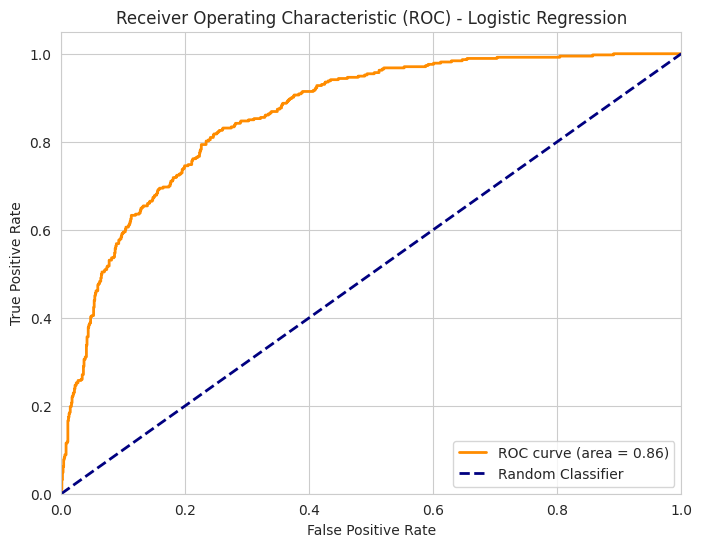

In [24]:
print("\n Logistic Regression Model Evaluation ")

y_pred_lr = lr_model.predict(X_test)
y_pred_proba_lr = lr_model.predict_proba(X_test)[:, 1]


accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy: {accuracy_lr:.4f}")

print("Classification Report:")
print(classification_report(y_test, y_pred_lr))


fpr_lr, tpr_lr, thresholds_lr = roc_curve(y_test, y_pred_proba_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)


plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_lr:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - Logistic Regression')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


 Random Forest Classifier Model Evaluation 
Accuracy: 0.8034
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.68      0.50      0.57       373

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



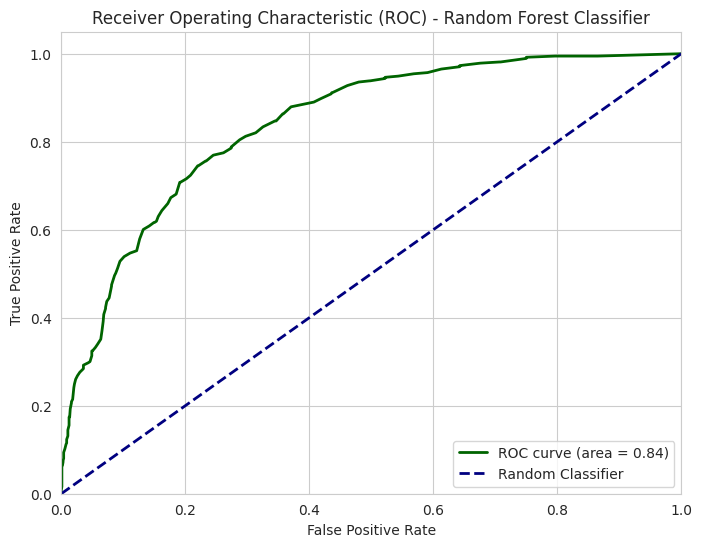

In [25]:
print("\n Random Forest Classifier Model Evaluation ")

y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]


accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Accuracy: {accuracy_rf:.4f}")


print("Classification Report:")
print(classification_report(y_test, y_pred_rf))


fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_pred_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='darkgreen', lw=2, label=f'ROC curve (area = {roc_auc_rf:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - Random Forest Classifier')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


 Gradient Boosting Classifier Model Evaluation 
Accuracy: 0.8077
Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1036
           1       0.67      0.54      0.60       373

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



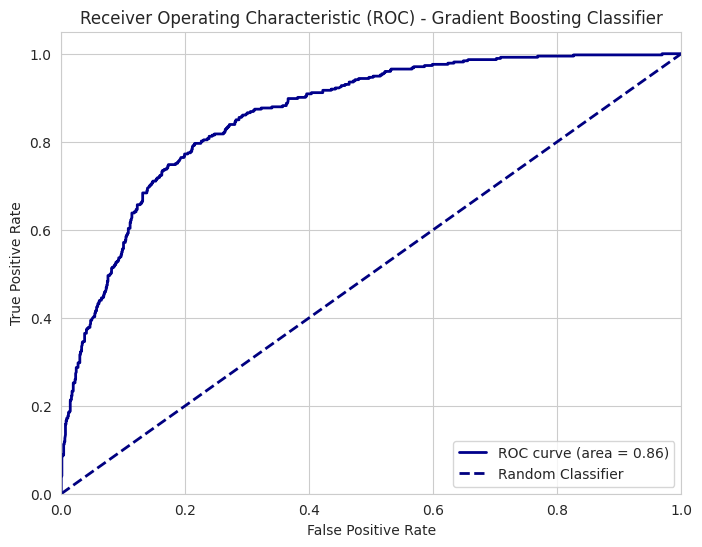

In [28]:
print("\n Gradient Boosting Classifier Model Evaluation ")

y_pred_gb = gb_model.predict(X_test)
y_pred_proba_gb = gb_model.predict_proba(X_test)[:, 1]

accuracy_gb = accuracy_score(y_test, y_pred_gb)
print(f"Accuracy: {accuracy_gb:.4f}")


print("Classification Report:")
print(classification_report(y_test, y_pred_gb))


fpr_gb, tpr_gb, thresholds_gb = roc_curve(y_test, y_pred_proba_gb)
roc_auc_gb = auc(fpr_gb, tpr_gb)


plt.figure(figsize=(8, 6))
plt.plot(fpr_gb, tpr_gb, color='darkblue', lw=2, label=f'ROC curve (area = {roc_auc_gb:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - Gradient Boosting Classifier')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()